# KontenKu AI — Pipeline Machine Learning\nNotebook untuk EDA, feature engineering, training Random Forest, evaluasi, dan ekspor model.\n\n**Catatan:** label viral dataset bukan jaminan video masuk FYP.

## Ringkasan pipeline
Notebook ini memakai dataset proyek yang sama, mengunduh CSV otomatis, lalu menjalankan EDA, feature engineering, training, evaluasi, dan ekspor model.


In [11]:
# KONTENKU AI — GOOGLE COLAB PIPELINE
# Dataset: Social Media Viral Content Dataset (2.000 baris)
# ============================================================
# Cara pakai:
# 1. Upload file CSV ke Colab saat diminta, atau letakkan di /content.
# 2. Jalankan cell dari atas ke bawah.
# 3. Notebook akan menghasilkan model .joblib + laporan evaluasi.
# Catatan: target "viral" pada dataset bukan jaminan masuk FYP.
# ============================================================


## Bagian 1 — Import library dan konfigurasi


In [12]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)
from sklearn.dummy import DummyClassifier
import joblib

RANDOM_STATE = 42
DATA_PATH = "/content/social_media_viral_content_dataset.csv"
MODEL_PATH = "/content/viral_classifier.joblib"

print("KontenKu AI — Pipeline Machine Learning siap.")


KontenKu AI — Pipeline Machine Learning siap.


## Bagian 2 — Mengunduh dataset proyek yang sama jika belum tersedia


In [13]:
# Dataset yang sama dengan proyek sebelumnya (2.000 baris, 15 kolom)
# Sumber mirror dataset: Hugging Face, file CSV asli dari dataset Kaggle.
import os
import pandas as pd

DATA_PATH = "/content/social_media_viral_content_dataset.csv"
DATA_URL = (
    "https://huggingface.co/datasets/"
    "jason1966/aliiihussain_social-media-viral-content-and-engagement-metrics/"
    "resolve/main/social_media_viral_content_dataset.csv"
)

if not os.path.exists(DATA_PATH):
    try:
        import requests
        response = requests.get(DATA_URL, timeout=60)
        response.raise_for_status()
        with open(DATA_PATH, "wb") as f:
            f.write(response.content)
        print("Dataset berhasil diunduh otomatis.")
    except Exception as e:
        print("Unduh otomatis gagal:", e)
        print("Silakan upload CSV yang sama secara manual.")
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise ValueError("File CSV tidak ditemukan.")
        DATA_PATH = "/content/" + csv_files[0]

df = pd.read_csv(DATA_PATH)
print("Lokasi dataset:", DATA_PATH)
print("Ukuran dataset:", df.shape)
display(df.head())
display(df.dtypes.to_frame("tipe_data"))


Lokasi dataset: /content/social_media_viral_content_dataset.csv
Ukuran dataset: (2000, 15)


,post_id,platform,content_type,topic,language,region,post_datetime,hashtags,views,likes,comments,shares,engagement_rate,sentiment_score,is_viral
0,SM_100000,Instagram,text,Sports,ur,UK,2024-12-10 00:00:00,#tech #funny #music,2319102,122058,15800,861,0.0598,0.464,1
1,SM_100001,Instagram,carousel,Sports,ur,Brazil,2024-10-13 00:00:00,#news #fyp #funny #ai #trending,2538464,110368,11289,54887,0.0695,-0.800,1
2,SM_100002,YouTube Shorts,video,Technology,ur,UK,2024-05-03 00:00:00,#ai #news,1051176,87598,47196,44132,0.1702,0.416,0
3,SM_100003,X,text,Politics,ur,US,2024-08-04 00:00:00,#ai #funny,5271440,329465,774,59736,0.0740,0.877,1
4,SM_100004,YouTube Shorts,text,Education,es,US,2024-03-28 00:00:00,#news #ai #viral #funny #fyp,3186256,199141,5316,83105,0.0903,0.223,1


,tipe_data
post_id,object
platform,object
content_type,object
topic,object
language,object
region,object
post_datetime,object
hashtags,object
views,int64
likes,int64


## Bagian 3 — Pemeriksaan data / EDA


Kolom: ['post_id', 'platform', 'content_type', 'topic', 'language', 'region', 'post_datetime', 'hashtags', 'views', 'likes', 'comments', 'shares', 'engagement_rate', 'sentiment_score', 'is_viral']
\nNilai kosong per kolom:


,jumlah_kosong
post_id,0
platform,0
content_type,0
topic,0
language,0
region,0
post_datetime,0
hashtags,0
views,0
likes,0


\nJumlah baris duplikat: 0
\nDistribusi target:


,jumlah
is_viral,
1,1398
0,602


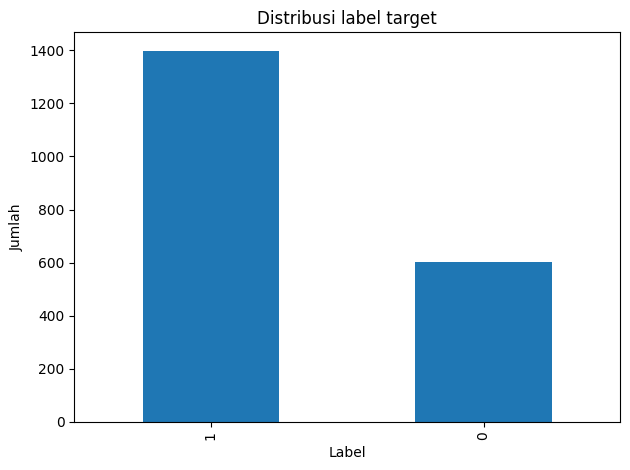

In [14]:
print("Kolom:", df.columns.tolist())
print("\\nNilai kosong per kolom:")
display(df.isna().sum().to_frame("jumlah_kosong"))
print("\\nJumlah baris duplikat:", df.duplicated().sum())

# Distribusi target
TARGET_CANDIDATES = ["is_viral", "viral", "isviral", "viral_label"]
target_col = next((c for c in TARGET_CANDIDATES if c in df.columns), None)
if target_col is None:
    # Tampilkan kolom agar nama target bisa diperiksa bila dataset berbeda.
    raise ValueError(
        "Kolom target viral tidak ditemukan. Kolom yang tersedia: "
        + ", ".join(df.columns)
        + ". Sesuaikan TARGET_CANDIDATES dengan nama label di dataset."
    )

print("\\nDistribusi target:")
display(df[target_col].value_counts(dropna=False).to_frame("jumlah"))
df[target_col].value_counts(dropna=False).plot(kind="bar", title="Distribusi label target")
plt.xlabel("Label")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()


## Bagian 4 — Feature engineering


In [15]:
# Dataset asli punya kolom `hashtags`, bukan `hashtag_count`.
# Karena itu kita hitung jumlah hashtag dari kolom `hashtags` agar cocok dengan CSV proyek.
# post_datetime selalu pada jam 00:00, jadi post_hour tidak digunakan.
required = [
    "platform", "content_type", "topic", "language", "region",
    "post_datetime", "hashtags", target_col
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing}. Kolom CSV: {df.columns.tolist()}")

def count_hashtags(value):
    if pd.isna(value):
        return 0
    value = str(value).strip()
    if not value:
        return 0
    # Jika ada simbol #, hitung tiap hashtag. Jika formatnya daftar dipisah koma/spasi,
    # hitung item yang tidak kosong.
    if "#" in value:
        return value.count("#")
    if "," in value:
        return len([part for part in value.split(",") if part.strip()])
    return len(value.split())

df["post_datetime"] = pd.to_datetime(df["post_datetime"], errors="coerce")
df["post_month"] = df["post_datetime"].dt.month
# Pandas dayofweek: Senin=0, Minggu=6
df["post_dayofweek"] = df["post_datetime"].dt.dayofweek
df["hashtag_count"] = df["hashtags"].apply(count_hashtags).astype(float)

categorical_features = ["platform", "content_type", "topic", "language", "region"]
numeric_features = ["post_month", "post_dayofweek", "hashtag_count"]
feature_cols = categorical_features + numeric_features

model_df = df[feature_cols + [target_col]].copy()
model_df = model_df.dropna(subset=[target_col])
X = model_df[feature_cols]
y = model_df[target_col]

print("Fitur yang digunakan:", feature_cols)
print("Jumlah data siap training:", len(model_df))
display(model_df.head())


Fitur yang digunakan: ['platform', 'content_type', 'topic', 'language', 'region', 'post_month', 'post_dayofweek', 'hashtag_count']
Jumlah data siap training: 2000


,platform,content_type,topic,language,region,post_month,post_dayofweek,hashtag_count,is_viral
0,Instagram,text,Sports,ur,UK,12,1,3.0,1
1,Instagram,carousel,Sports,ur,Brazil,10,6,5.0,1
2,YouTube Shorts,video,Technology,ur,UK,5,4,2.0,0
3,X,text,Politics,ur,US,8,6,2.0,1
4,YouTube Shorts,text,Education,es,US,3,3,5.0,1


## Bagian 5 — Split data dan preprocessing


In [16]:
# Stratify mempertahankan proporsi kelas pada train dan test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features),
])

# Baseline mayoritas: pembanding sederhana untuk mengecek apakah model memberi nilai tambah.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)


## Bagian 6 — Training model Random Forest


In [17]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training selesai.")


Training selesai.


## Bagian 7 — Evaluasi model


=== HASIL MODEL ===
Accuracy: 0.645
Balanced accuracy: 0.475
\nClassification report:
              precision    recall  f1-score   support

           0       0.18      0.05      0.08       120
           1       0.69      0.90      0.78       280

    accuracy                           0.65       400
   macro avg       0.43      0.48      0.43       400
weighted avg       0.53      0.65      0.57       400

=== BASELINE MAYORITAS ===
Accuracy baseline: 0.7
Balanced accuracy baseline: 0.5


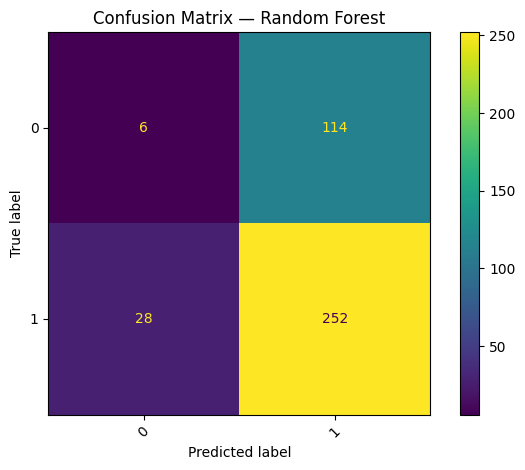

ROC AUC: 0.4576


In [18]:
print("=== HASIL MODEL ===")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("=== BASELINE MAYORITAS ===")
print("Accuracy baseline:", round(accuracy_score(y_test, baseline_pred), 4))
print("Balanced accuracy baseline:", round(balanced_accuracy_score(y_test, baseline_pred), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=45)
plt.title("Confusion Matrix — Random Forest")
plt.tight_layout()
plt.show()

# ROC AUC hanya untuk klasifikasi biner dan jika model menyediakan predict_proba
try:
    if len(np.unique(y_test)) == 2:
        probs = model.predict_proba(X_test)[:, 1]
        print("ROC AUC:", round(roc_auc_score(y_test, probs), 4))
except Exception as e:
    print("ROC AUC tidak dapat dihitung:", e)


## Bagian 8 — Simpan artefak model dan laporan


In [19]:
joblib.dump(model, MODEL_PATH)
report_path = "/content/model_evaluation.txt"
with open(report_path, "w", encoding="utf-8") as f:
    f.write("KONTENKU AI — MODEL EVALUATION\\n")
    f.write(f"Dataset rows: {len(df)}\\n")
    f.write(f"Features: {feature_cols}\\n")
    f.write(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\\n")
    f.write(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}\\n")
    f.write(f"Baseline accuracy: {accuracy_score(y_test, baseline_pred):.4f}\\n")
    f.write(f"Baseline balanced accuracy: {balanced_accuracy_score(y_test, baseline_pred):.4f}\\n")
    f.write("\\nClassification report:\\n")
    f.write(classification_report(y_test, y_pred, zero_division=0))

print("Model tersimpan:", MODEL_PATH)
print("Laporan tersimpan:", report_path)


Model tersimpan: /content/viral_classifier.joblib
Laporan tersimpan: /content/model_evaluation.txt


## Bagian 9 — Download model + laporan untuk dipakai di aplikasi Streamlit


In [20]:
from google.colab import files
files.download(MODEL_PATH)
files.download(report_path)

# Setelah file terdownload, salin viral_classifier.joblib ke:
# C:\\Users\\<USERNAME>\\Documents\\kontenku-ai\\models\\viral_classifier.joblib
# Salin model_evaluation.txt ke folder reports bila dibutuhkan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>